# 1. Most "jumps" are not jumps

**Series: Jumps in financial time series**

A jump test flags a discontinuity whenever one return is too large for the volatility around it. That verdict depends on the sampling clock. A volatility burst that lasts a few minutes is a continuous move, yet on a 15-minute grid it lands in a single return and is indistinguishable from a jump.

Christensen, Oomen and Podolskij (2014) showed this on tick data: the jump share of variance in equities and FX falls from around 10% at 5-minute sampling to about 1% at tick frequency.

This notebook does two things:

1. **Controlled experiment.** Simulate one world with volatility bursts and *no jumps*, and one with genuine jumps, then measure both at sampling intervals from 5 seconds to 1 hour.
2. **Crypto data.** Run the same measurement on BTC and ETH 1-minute bars from Binance's public archive (no API key needed).

## Setup

Log price with stochastic volatility and finite-activity jumps:

$$X_t = X_0 + \int_0^t \mu_s\,ds + \int_0^t \sigma_s\,dW_s + \sum_{k=1}^{N_t} J_k$$

Over one day, with $n$ intraday returns $r_i$:

$$\mathrm{RV} = \sum_{i=1}^{n} r_i^2 \;\longrightarrow\; \int_0^1 \sigma_s^2\,ds + \sum_{k} J_k^2$$

$$\mathrm{BV} = \frac{\pi}{2}\,\frac{n}{n-1}\sum_{i=2}^{n} |r_i|\,|r_{i-1}| \;\longrightarrow\; \int_0^1 \sigma_s^2\,ds$$

A jump enters one return only, so the product of adjacent absolute returns kills it in the limit. The difference isolates the jump part, and the relative jump measure is

$$\mathrm{RJ} = \frac{\mathrm{RV} - \mathrm{BV}}{\mathrm{RV}}$$

The Barndorff-Nielsen and Shephard test, in the ratio form of Huang and Tauchen (2005), is asymptotically standard normal on a day without jumps:

$$z = \frac{\mathrm{RJ}}{\sqrt{\left(\frac{\pi^2}{4} + \pi - 5\right)\frac{1}{n}\,\max\!\left(1, \frac{\mathrm{TQ}}{\mathrm{BV}^2}\right)}}$$

where TQ is tripower quarticity. The catch is in "the limit": the result needs volatility to be roughly constant across *adjacent* returns. A burst shorter than the sampling interval breaks that.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jumps import plotting as jp
from jumps.data import load_klines, to_daily_grid
from jumps.estimators import bns_jump_test, jump_summary, subsample_returns
from jumps.simulate import simulate_log_prices

jp.set_style()

## Equation images for the post

LinkedIn does not render LaTeX, so the key equations are exported as images.

In [2]:
jp.render_equation(r"\mathrm{RV}=\sum_{i=1}^{n} r_i^2\ \rightarrow\ \int_0^1\sigma_s^2\,ds+\sum_k J_k^2",
                   "01_eq_rv", "Realized variance captures diffusion and jumps")
jp.render_equation(r"\mathrm{BV}=\dfrac{\pi}{2}\sum_{i=2}^{n}|r_i|\,|r_{i\!-\!1}|\ \rightarrow\ \int_0^1\sigma_s^2\,ds",
                   "01_eq_bv", "Bipower variation captures diffusion only")
jp.render_equation(r"\mathrm{RJ}=\dfrac{\mathrm{RV}-\mathrm{BV}}{\mathrm{RV}}",
                   "01_eq_rj", "Relative jump measure: the share of variance attributed to jumps");

## Part 1. A controlled experiment

Both worlds share a persistent daily volatility level and an intraday periodic pattern, at 50% annualised volatility, simulated on a 5-second grid.

- **Bursts world:** volatility spikes to 10-25 times its level about once every two days and decays with a 60-second half-life. The path is continuous. The true jump share is 0%.
- **Jumps world:** no bursts. Genuine jumps arrive at the same rate and carry 10% of total variance.

In [3]:
DT = 5  # seconds
INTERVALS = {"5s": 5, "15s": 15, "1m": 60, "5m": 300, "15m": 900, "30m": 1800, "1h": 3600}
LABELS = list(INTERVALS)
sim_steps = [s // DT for s in INTERVALS.values()]

bursts = simulate_log_prices("bursts", n_days=300, dt_seconds=DT, seed=0)
jumps = simulate_log_prices("jumps", n_days=300, dt_seconds=DT, seed=0)

sim = {"Bursts, no jumps": jump_summary(bursts, sim_steps),
       "True jumps": jump_summary(jumps, sim_steps)}

sim_table = pd.DataFrame({name: 100 * res["jump_share"] for name, res in sim.items()}, index=LABELS)
sim_table.round(1).rename_axis("Sampling interval").style.format("{:.1f}%").set_caption("Estimated jump share of variance")

,"Bursts, no jumps",True jumps
Sampling interval,,
5s,0.7%,10.9%
15s,1.5%,10.5%
1m,3.7%,10.1%
5m,8.7%,8.7%
15m,8.5%,7.5%
30m,8.0%,6.5%
1h,8.6%,8.3%


The burst world contains no jumps, yet from 5-minute sampling upward it reports the same jump share as the world that has them. Only the fine grid tells them apart.

### The same event on two clocks

The window below is the burst that produces the most extreme 15-minute return in the simulation.

15-minute return: 12.3 local standard deviations


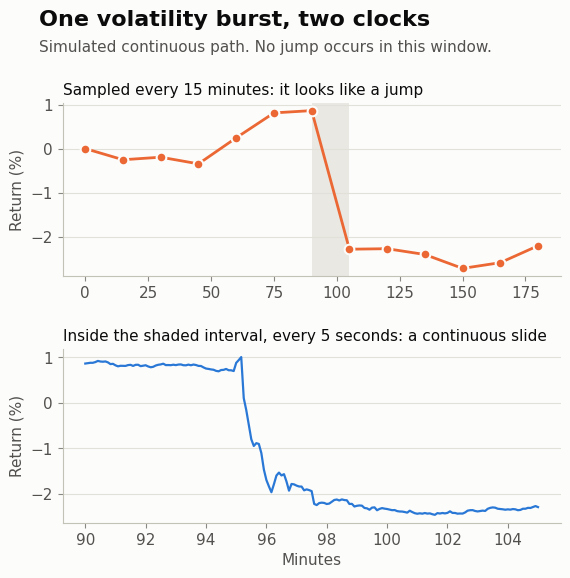

In [4]:
COARSE = 900  # 15 minutes
k = COARSE // DT
r15 = subsample_returns(bursts, k)
score = np.abs(r15) / np.sqrt(bns_jump_test(r15)["bv"][:, None] / r15.shape[1])
day, i = np.unravel_index(np.argmax(score), score.shape)
lo = int(np.clip((i - 6) * k, 0, bursts.shape[1] - 12 * k - 1))
window = bursts[day, lo : lo + 12 * k + 1]

fig = jp.two_clocks_plot(window, DT, COARSE, event_index=(i * k - lo) // k,
                         title="One volatility burst, two clocks",
                         subtitle="Simulated continuous path. No jump occurs in this window.")
jp.save(fig, "01_two_clocks");
print(f"15-minute return: {score[day, i]:.1f} local standard deviations")

## Part 2. BTC and ETH

One-minute bars from Binance's public archive, cached under `data/` after the first run. The finest interval available here is 1 minute, so the empirical curves start at the third point of the simulated ones.

To use your own data instead, build a `pd.Series` of 1-minute closes indexed by UTC time and pass it to `to_daily_grid`.

In [5]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
START, END = "2023-01", "2024-12"
EMP_INTERVALS = ["1m", "5m", "15m", "30m", "1h"]
emp_steps = [INTERVALS[k] // 60 for k in EMP_INTERVALS]

empirical = {}
try:
    for symbol in SYMBOLS:
        grid = to_daily_grid(load_klines(symbol, START, END)["close"])
        empirical[symbol] = jump_summary(grid.to_numpy(), emp_steps)
        print(f"{symbol}: {len(grid)} complete days")
except OSError as exc:
    print(f"Binance archive not reachable ({exc}). Skipping the empirical section.")

BTCUSDT 1m: 24 months loaded


BTCUSDT: 729 complete days


ETHUSDT 1m: 24 months loaded
ETHUSDT: 729 complete days


In [6]:
if empirical:
    emp_table = pd.concat(
        {"Jump share": pd.DataFrame({s: 100 * r["jump_share"] for s, r in empirical.items()}, index=EMP_INTERVALS),
         "Days flagged at 1%": pd.DataFrame({s: 100 * r["days_flagged"] for s, r in empirical.items()}, index=EMP_INTERVALS)},
        axis=1)
    display(emp_table.round(1).rename_axis("Sampling interval"))

Jump share         Days flagged at 1%        
                     BTCUSDT ETHUSDT            BTCUSDT ETHUSDT
Sampling interval                                              
1m                       3.5     3.8               29.4    27.8
5m                       6.2     8.0               13.4    17.6
15m                      5.9     8.6                8.9    12.3
30m                      7.8    10.1                8.6    11.1
1h                      12.7    13.7                9.2    10.2

## The chart

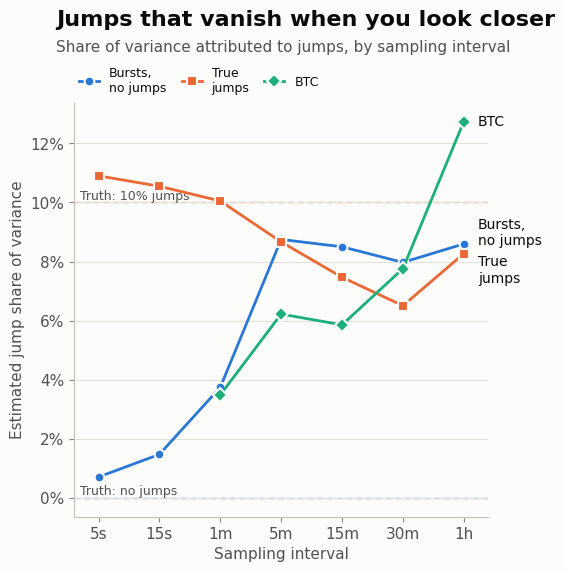

In [7]:
x_sim = list(range(len(LABELS)))
series = [
    {"name": "Bursts,\nno jumps", "x": x_sim, "y": 100 * sim["Bursts, no jumps"]["jump_share"], "color": jp.BLUE, "dy": 8},
    {"name": "True\njumps", "x": x_sim, "y": 100 * sim["True jumps"]["jump_share"], "color": jp.ORANGE, "marker": "s", "dy": -12},
]
if "BTCUSDT" in empirical:
    x_emp = [LABELS.index(k) for k in EMP_INTERVALS]
    series.append({"name": "BTC", "x": x_emp, "y": 100 * empirical["BTCUSDT"]["jump_share"],
                   "color": jp.AQUA, "marker": "D"})

fig = jp.signature_plot(
    series, LABELS,
    truth=[{"y": 10, "color": jp.ORANGE, "text": "Truth: 10% jumps"},
           {"y": 0, "color": jp.BLUE, "text": "Truth: no jumps"}],
    title="Jumps that vanish when you look closer",
    subtitle="Share of variance attributed to jumps, by sampling interval",
    ylabel="Estimated jump share of variance",
)
jp.save(fig, "01_jump_share_by_sampling");

## How often does the test cry jump?

Share of days on which the BNS test rejects "no jumps" at the 1% level. In the burst world every rejection is a false positive.

In [8]:
flag_table = pd.DataFrame({name: 100 * res["days_flagged"] for name, res in sim.items()}, index=LABELS)
for symbol, res in empirical.items():
    flag_table[symbol] = pd.Series(100 * res["days_flagged"], index=EMP_INTERVALS)
flag_table.round(1).rename_axis("Sampling interval")

,"Bursts, no jumps",True jumps,BTCUSDT,ETHUSDT
Sampling interval,,,,
5s,3.7,33.7,NaN,NaN
15s,6.3,31.7,NaN,NaN
1m,10.3,26.7,29.4,27.8
5m,13.0,21.3,13.4,17.6
15m,12.0,14.3,8.9,12.3
30m,8.3,7.7,8.6,11.1
1h,7.3,9.0,9.2,10.2


## Takeaways

- A jump is a statement about the limit, and an estimate of it is a statement about your sampling clock.
- At 5 minutes and coarser, a world with zero jumps and a world with 10% jump variance produce the same bipower-based jump share.
- The test is oversized even on the finest grid, because intraday periodicity also violates locally constant volatility. That is the subject of notebook 2.
- One-minute bars narrow the gap but do not close it. Resolving bursts from jumps needs tick data and noise-robust estimators.

## References

- Barndorff-Nielsen, O. E. and Shephard, N. (2004). Power and bipower variation with stochastic volatility and jumps. *Journal of Financial Econometrics*.
- Barndorff-Nielsen, O. E. and Shephard, N. (2006). Econometrics of testing for jumps in financial economics using bipower variation. *Journal of Financial Econometrics*.
- Huang, X. and Tauchen, G. (2005). The relative contribution of jumps to total price variance. *Journal of Financial Econometrics*.
- Christensen, K., Oomen, R. C. A. and Podolskij, M. (2014). Fact or friction: Jumps at ultra high frequency. *Journal of Financial Economics*.